In [ ]:
import numpy as np
import pandas as pd

In [ ]:
real_train = pd.read_csv(r".../Train/SGA_train.csv")
real_train = real_train.drop(columns=['A', 'B','C', 'D', 'Necrotizing Enterocolitis '])

In [ ]:
real_test= pd.read_csv(r".../Test/SGA_test.csv")
real_test = real_test.drop(columns=['A', 'B','C', 'D', 'Necrotizing Enterocolitis '])

In [ ]:
syn = pd.read_csv(r"..../SGA_smote/Synthetic.csv")
syn_df = syn_df.drop(columns=['A', 'B','C', 'D', 'Necrotizing Enterocolitis '])

In [ ]:
# -------------------------------------------------------
# Distance to Closest Record (DCR)
# Nearest-neighbor disclosure analysis
# -------------------------------------------------------

synthetic_df = syn_df.copy()

# Use the same features across all datasets
cols = (
    real_train.columns
    .intersection(real_test.columns)
    .intersection(synthetic_df.columns)
)

print("Number of features used:", len(cols))


# -------------------------------------------------------
# Hamming distance
# Same distance metric used in MIA
# -------------------------------------------------------

def hamming_distances_to_synthetic(row, synthetic_df, cols):

    r = row[cols].to_numpy()
    S = synthetic_df[cols].to_numpy()

    # Number of mismatching features / total features
    mismatches = (S != r)

    distances = (
        mismatches.sum(axis=1) /
        float(len(cols))
    )

    return distances


# -------------------------------------------------------
# Calculate minimum distance to synthetic data
# -------------------------------------------------------

def calculate_dcr(real_df, synthetic_df, cols):

    dcr = []

    for _, row in real_df.iterrows():

        distances = hamming_distances_to_synthetic(
            row,
            synthetic_df,
            cols
        )

        # Distance to closest synthetic record
        dcr.append(distances.min())

    return np.array(dcr)


# REAL TRAIN -> SYNTHETIC
train_dcr = calculate_dcr(
    real_train,
    synthetic_df,
    cols
)

# REAL TEST -> SYNTHETIC
test_dcr = calculate_dcr(
    real_test,
    synthetic_df,
    cols
)

print("Train records:", len(train_dcr))
print("Test records:", len(test_dcr))

In [ ]:
dcr_summary = pd.DataFrame({

    "Comparison": [
        "Real train → Synthetic",
        "Real test → Synthetic"
    ],

    "Mean DCR": [
        np.mean(train_dcr),
        np.mean(test_dcr)
    ],

    "SD": [
        np.std(train_dcr, ddof=1),
        np.std(test_dcr, ddof=1)
    ],

    "Median DCR": [
        np.median(train_dcr),
        np.median(test_dcr)
    ],

    "Q1": [
        np.percentile(train_dcr, 25),
        np.percentile(test_dcr, 25)
    ],

    "Q3": [
        np.percentile(train_dcr, 75),
        np.percentile(test_dcr, 75)
    ],

    "Minimum DCR": [
        np.min(train_dcr),
        np.min(test_dcr)
    ]
})

display(dcr_summary.round(4))

In [ ]:
print("EXACT MATCHES")
print("---------------------------")

print(
    "Real train → Synthetic:",
    np.sum(train_dcr == 0)
)

print(
    "Real test → Synthetic:",
    np.sum(test_dcr == 0)
)


print("\nDCR < 0.05")
print("---------------------------")

print(
    "Real train:",
    np.mean(train_dcr < 0.05)
)

print(
    "Real test:",
    np.mean(test_dcr < 0.05)
)


print("\nDCR < 0.10")
print("---------------------------")

print(
    "Real train:",
    np.mean(train_dcr < 0.10)
)

print(
    "Real test:",
    np.mean(test_dcr < 0.10)
)

In [ ]:
from scipy.stats import mannwhitneyu

stat, p_value = mannwhitneyu(
    train_dcr,
    test_dcr,
    alternative="two-sided"
)

print("Mann–Whitney U test")
print("---------------------------")
print("U statistic:", stat)
print("p-value:", p_value)

In [ ]:
# Plot

In [ ]:
import matplotlib.pyplot as plt

def ecdf(data):
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y


x_train, y_train = ecdf(train_dcr)
x_test, y_test_dcr = ecdf(test_dcr)

plt.figure(figsize=(7, 5))

plt.plot(
    x_train,
    y_train,
    linewidth=2,
    label="Real train → Synthetic"
)

plt.plot(
    x_test,
    y_test_dcr,
    linewidth=2,
    label="Real test → Synthetic"
)

plt.xlabel("Hamming distance to closest synthetic record (DCR)")
plt.ylabel("Cumulative Proportion")

plt.legend(frameon=False)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

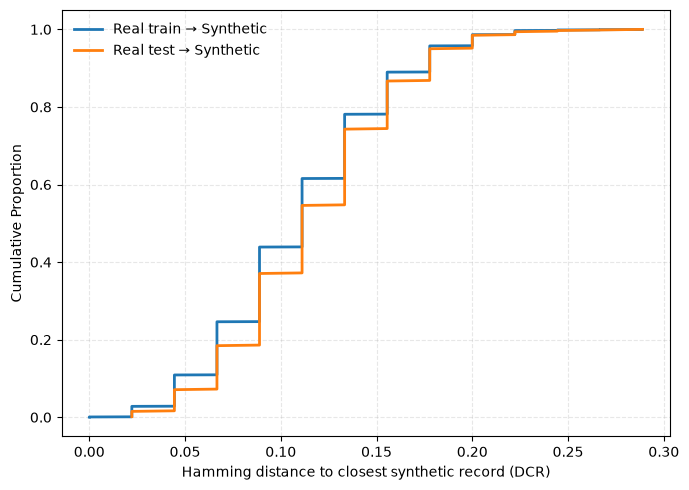